# Machine Learning Workflow: Issues, Applications, and Project Steps

The algorithm notebooks show how individual models work. This notebook covers the part of
CSC604 Module 1 that sits around the algorithms: what can go wrong, where ML is used, and how a
project moves from a business question to a monitored model.

## Learning objectives

By the end of this notebook you can:

- name the main technical and organisational issues in ML projects;
- describe common ML application areas and the type of task each one uses;
- list the steps of developing an ML application and the artifact produced at each step;
- run a small end-to-end workflow with train, validation, and test splits;
- explain why accuracy alone is not enough and compute specificity alongside sensitivity.

## 1. Issues in machine learning

Most failed ML projects fail for reasons that are not the choice of algorithm. The table below
groups the common issues and the practical response.

| Area | Typical issue | What to do |
| --- | --- | --- |
| Data | Too little data for the complexity of the question | Start with a simpler model, collect more data, or use transfer learning |
| Data | Sample is not representative of the deployment population | Audit data provenance, compare train and production distributions |
| Data | Missing values, duplicates, inconsistent labels | Profile the data, define an imputation rule, and track label quality |
| Data | Class imbalance hides poor minority-class performance | Use precision, recall, F1, PR-AUC, and stratified splits |
| Model | Underfitting: the model is too simple | Add features, increase capacity, check for label noise |
| Model | Overfitting: the model memorises the training set | Regularise, simplify, collect more data, use early stopping |
| Evaluation | Leakage: information from the target or future leaks into features | Split before fitting preprocessing; use time-aware validation |
| Evaluation | Test set reused during model selection | Keep a final hold-out test set and touch it once |
| Evaluation | One aggregate metric hides subgroup failures | Report metrics by segment and inspect errors |
| Operations | Data drift or concept drift after deployment | Monitor inputs, predictions, and outcomes; define retraining triggers |
| Operations | Latency, cost, or maintenance exceed the budget | Measure inference cost and choose a model that fits the constraints |
| Responsible AI | Unfair or unexplainable decisions | Measure group-level performance, document limitations, add human review |

## 2. Applications of machine learning

| Domain | Example task | Learning type |
| --- | --- | --- |
| Healthcare | Disease risk prediction from clinical measurements | Supervised classification |
| Finance | Fraud detection and credit risk scoring | Supervised classification |
| Retail | Demand forecasting and customer segmentation | Regression and clustering |
| Manufacturing | Predictive maintenance from sensor data | Supervised classification or regression |
| Marketing | Churn prediction and recommendation | Classification and ranking |
| Natural language | Spam filtering, sentiment analysis, topic discovery | Classification and unsupervised learning |
| Computer vision | Defect detection and image tagging | Classification (usually deep learning) |
| Transport | Route optimisation and arrival-time prediction | Optimisation and regression |

The task type follows from the target: a continuous target suggests regression, a categorical
target suggests classification, and no target suggests clustering or another unsupervised method.

## 3. Steps of developing an ML application

1. **Frame the problem.** Translate the business objective into a measurable prediction target and
   success metric. Artifact: problem statement and success criteria.
2. **Collect and govern the data.** Identify sources, permissions, privacy constraints, and label
   definitions. Artifact: data inventory and data dictionary.
3. **Explore and prepare the data.** Profile distributions, missing values, duplicates, and
   outliers. Artifact: EDA report and cleaning plan.
4. **Engineer and select features.** Build representations that expose the signal without leaking
   the target. Artifact: feature specification and preprocessing pipeline.
5. **Choose the validation strategy.** Create train, validation, and test splits that match how the
   model will be used. Artifact: split definition and evaluation protocol.
6. **Establish a baseline.** Use a simple rule or a dummy model so every later result has context.
   Artifact: baseline score.
7. **Train and tune models.** Compare candidate algorithms and hyperparameters using only the
   training and validation data. Artifact: model comparison table.
8. **Evaluate and analyse errors.** Report the agreed metrics, inspect confusion matrices, and
   check important subgroups. Artifact: evaluation report.
9. **Deploy.** Package the preprocessing and model together and expose a stable interface.
   Artifact: service, batch job, or embedded model.
10. **Monitor and maintain.** Track data quality, drift, performance, and cost; retrain when the
    monitoring rules trigger. Artifact: monitoring dashboard and retraining plan.

The most common process mistake is doing step 8 before step 5, or repeating step 7 until the test
set is effectively another validation set.

## 4. End-to-end example

We will use the built-in Breast Cancer Wisconsin dataset. To make the metrics easier to interpret,
the target is encoded so that **malignant = 1** and **benign = 0**. The workflow is:

1. split into train, validation, and test sets;
2. fit a dummy baseline;
3. tune a logistic-regression pipeline with cross-validation on the training set;
4. compare the tuned model with the baseline on the validation set;
5. evaluate the chosen model once on the test set.

In [1]:
import warnings

warnings.filterwarnings("ignore", message="A NumPy version")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

In [2]:
data = load_breast_cancer(as_frame=True)
X = data.data
y = (data.target == 0).astype(int)
class_names = ["benign", "malignant"]

print("Rows, features:", X.shape)
print("Class balance:")
print(y.value_counts(normalize=True).rename(index={0: "benign", 1: "malignant"}).round(3))

Rows, features: (569, 30)
Class balance:
target
benign       0.627
malignant    0.373
Name: proportion, dtype: float64


In [3]:
X.describe().T[["mean", "std", "min", "max"]].head(8).round(2)

,mean,std,min,max
mean radius,14.13,3.52,6.98,28.11
mean texture,19.29,4.30,9.71,39.28
mean perimeter,91.97,24.30,43.79,188.50
mean area,654.89,351.91,143.50,2501.00
mean smoothness,0.10,0.01,0.05,0.16
mean compactness,0.10,0.05,0.02,0.35
mean concavity,0.09,0.08,0.00,0.43
mean concave points,0.05,0.04,0.00,0.20


### Create the splits

The validation set is used for model comparison and threshold selection. The test set is held
back until the end.

In [4]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25, stratify=y_train_full, random_state=RANDOM_STATE
)

print("train:", X_train.shape[0])
print("validation:", X_val.shape[0])
print("test:", X_test.shape[0])

train: 341
validation: 114
test: 114


### A shared metric function

Specificity is the share of true negatives that the model correctly identifies:

$$\text{specificity} = \frac{TN}{TN + FP}$$

Sensitivity (recall) is the share of true positives that the model finds:

$$\text{sensitivity} = \frac{TP}{TP + FN}$$

In this notebook, a positive prediction means "malignant", so sensitivity is the fraction of
malignant cases detected and specificity is the fraction of benign cases correctly cleared.

In [5]:
def binary_metrics(y_true, y_pred, y_prob=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall_sensitivity": recall_score(y_true, y_pred, zero_division=0),
        "specificity": tn / (tn + fp) if (tn + fp) else 0.0,
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }
    if y_prob is not None:
        metrics["roc_auc"] = roc_auc_score(y_true, y_prob)
    return metrics

### Baseline first

A baseline is not optional. It tells us whether the model is learning anything useful. The
most-frequent classifier predicts the majority class for every row.

In [6]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_metrics = binary_metrics(
    y_val,
    baseline.predict(X_val),
    baseline.predict_proba(X_val)[:, 1],
)
baseline_metrics

{'accuracy': 0.6228070175438597,
 'precision': np.float64(0.0),
 'recall_sensitivity': np.float64(0.0),
 'specificity': np.float64(1.0),
 'f1': np.float64(0.0),
 'roc_auc': np.float64(0.5)}

### Tune a logistic-regression pipeline

The scaler is fitted inside each cross-validation fold by the pipeline. This avoids leaking
validation information into the preprocessing.

In [7]:
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
)

param_grid = {"logisticregression__C": [0.01, 0.1, 1.0, 10.0, 100.0]}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

search = GridSearchCV(
    model,
    param_grid=param_grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
)
search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print("Best cross-validated ROC-AUC:", round(search.best_score_, 3))

Best parameters: {'logisticregression__C': 1.0}
Best cross-validated ROC-AUC: 0.994


In [8]:
val_pred = search.predict(X_val)
val_prob = search.predict_proba(X_val)[:, 1]
model_metrics = binary_metrics(y_val, val_pred, val_prob)

comparison = pd.DataFrame(
    {"dummy_baseline": baseline_metrics, "tuned_logistic": model_metrics}
)
comparison.round(3)

,dummy_baseline,tuned_logistic
accuracy,0.623,0.974
precision,0.000,0.955
recall_sensitivity,0.000,0.977
specificity,1.000,0.972
f1,0.000,0.966
roc_auc,0.500,0.996


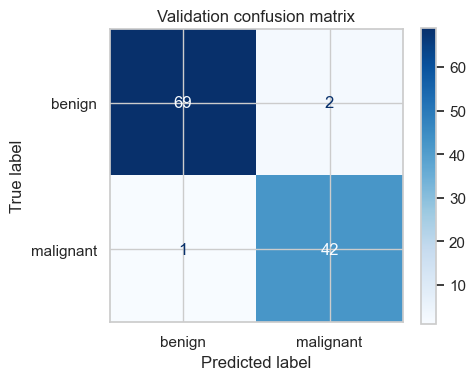

In [9]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_pred,
    display_labels=class_names,
    cmap="Blues",
    ax=ax,
)
ax.set_title("Validation confusion matrix")
plt.tight_layout()
plt.show()

The tuned model improves sensitivity dramatically compared with the baseline. That matters because
the baseline can look acceptable on accuracy while missing every malignant case.

### Threshold trade-off

A classifier outputs a probability. The default threshold is 0.5, but the right threshold depends
on the cost of a false negative versus a false positive. The table and plot below show how
sensitivity and specificity move as the threshold changes.

In [10]:
thresholds = np.arange(0.05, 0.96, 0.05)
rows = []
for threshold in thresholds:
    pred_at_threshold = (val_prob >= threshold).astype(int)
    row = {"threshold": round(float(threshold), 2)}
    row.update(binary_metrics(y_val, pred_at_threshold))
    rows.append(row)

threshold_table = pd.DataFrame(rows)
threshold_table.round(3).head(10)

,threshold,accuracy,precision,recall_sensitivity,specificity,f1
0,0.05,0.851,0.717,1.000,0.761,0.835
1,0.10,0.886,0.768,1.000,0.817,0.869
2,0.15,0.904,0.808,0.977,0.859,0.884
3,0.20,0.921,0.840,0.977,0.887,0.903
4,0.25,0.930,0.857,0.977,0.901,0.913
5,0.30,0.956,0.913,0.977,0.944,0.944
6,0.35,0.974,0.955,0.977,0.972,0.966
7,0.40,0.974,0.955,0.977,0.972,0.966
8,0.45,0.974,0.955,0.977,0.972,0.966
9,0.50,0.974,0.955,0.977,0.972,0.966


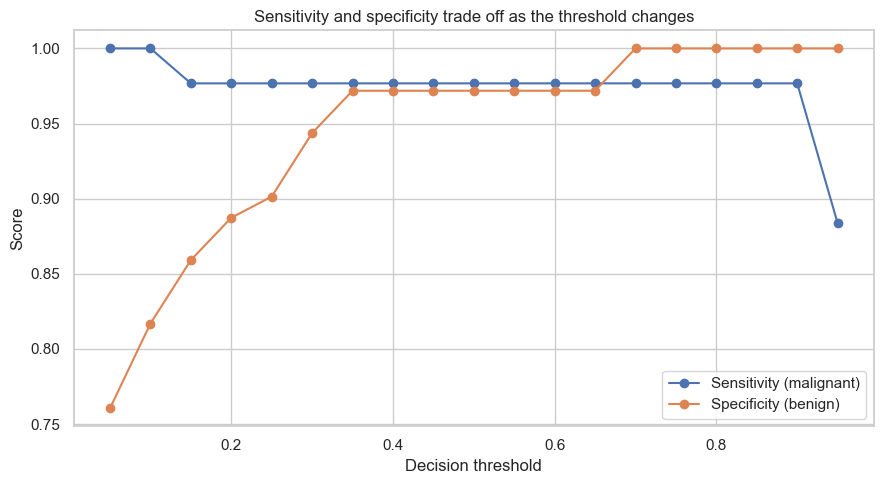

In [11]:
plt.figure(figsize=(9, 5))
plt.plot(
    threshold_table["threshold"],
    threshold_table["recall_sensitivity"],
    marker="o",
    label="Sensitivity (malignant)",
)
plt.plot(
    threshold_table["threshold"],
    threshold_table["specificity"],
    marker="o",
    label="Specificity (benign)",
)
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title("Sensitivity and specificity trade off as the threshold changes")
plt.legend()
plt.tight_layout()
plt.show()

### Final test evaluation

The test set is used once, after the model and threshold have been chosen. If we used it to choose
the threshold, it would no longer be a fair estimate of performance on unseen data.

In [12]:
test_pred = search.predict(X_test)
test_prob = search.predict_proba(X_test)[:, 1]
test_metrics = binary_metrics(y_test, test_pred, test_prob)

pd.Series(test_metrics).round(3).to_frame("test_score")

,test_score
accuracy,0.974
precision,0.976
recall_sensitivity,0.952
specificity,0.986
f1,0.964
roc_auc,0.995


## 5. Project checklist

Use this checklist before calling a model finished:

- The problem statement names the prediction target, the decision, and the cost of errors.
- The data source, permissions, and label definition are documented.
- The split matches deployment: random for i.i.d. data, grouped for users or sites, time-ordered
  for forecasting.
- All preprocessing is fitted inside the training data only.
- A baseline is reported next to every model.
- The metric matches the decision, and subgroup performance is checked.
- The test set is untouched until the final evaluation.
- The model card records limitations, assumptions, and monitoring plans.

## Key takeaways

- ML projects fail more often from data, evaluation, and operational problems than from the choice
  of algorithm.
- A baseline and a clean validation protocol are the fastest way to avoid self-deception.
- Accuracy is not enough for imbalanced or high-cost decisions; report sensitivity and specificity.
- Deployment is not the end. Monitoring and retraining are part of the lifecycle.

## Exercises

1. Replace logistic regression with a random forest and compare validation metrics.
2. Choose a threshold that keeps sensitivity above 0.95. Report the specificity cost.
3. Add a calibration curve and explain whether the predicted probabilities are trustworthy.
4. Introduce a missing-value column and impute it inside the pipeline.
5. Write a one-page project charter for a problem in your own domain using the ten steps above.